# RASR tutorial

This notebook loads a trained RASR checkpoint, fits it to two datasets, and shows the predicted
expression together with its Pareto front of fit vs. expression size.

Setup: install the package with the `notebook` extra as described in the README's
[Setup](../README.md#setup) section, e.g. `uv sync --group gpu --extra notebook`.

## Load a trained checkpoint

`MODEL_PATH` is a Hugging Face model ID, here the default `RASR-94M-L`. The weights are downloaded
on first use. A local checkpoint folder works as well.

In [ ]:
import numpy as np
import torch
from sklearn.metrics import r2_score

from src.rasr.inference.rasr import RASR

MODEL_PATH = "davidotte/RASR-94M-L"

model = RASR(
    model_path=MODEL_PATH,
    device="cuda" if torch.cuda.is_available() else "cpu",
    num_candidates=256,  # Decrease when running on CPU.
    decode_batch_size=16,
    n_restarts=4,
    parsimony=0.01,
    verbose=True,
)

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

## 1. Draw your own 1D dataset

Click to draw `(x, y)` points and see which expression RASR finds for them. The drawing widget
needs the `ipympl` backend from the `notebook` extra. If it doesn't render in your environment,
skip to section 2.

In [2]:
%matplotlib widget

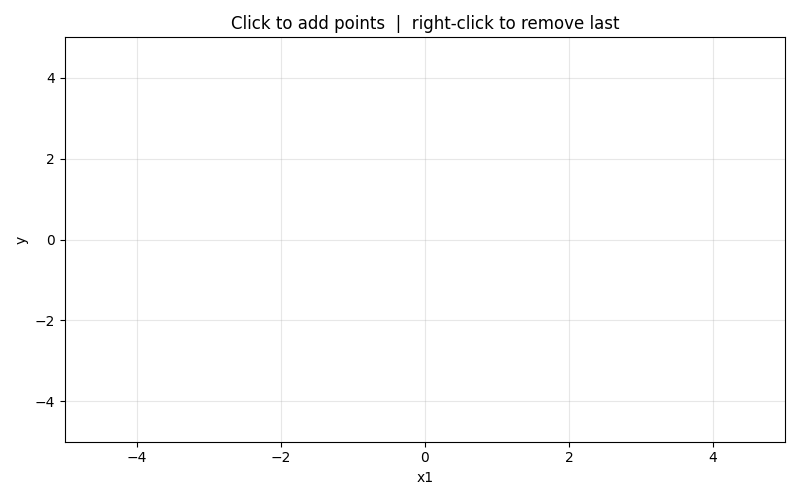

In [5]:
import matplotlib.pyplot as plt

_clicked_x: list[float] = []
_clicked_y: list[float] = []

fig, ax = plt.subplots(figsize=(8, 5))
fig.canvas.toolbar_visible = False
fig.canvas.header_visible = False
ax.set_xlim(-5, 5)
ax.set_ylim(-5, 5)
ax.set_xlabel("x1")
ax.set_ylabel("y")
ax.set_title("Click to add points  |  right-click to remove last")
ax.grid(alpha=0.3)
(scatter,) = ax.plot([], [], "o", color="steelblue", ms=6, zorder=3)


def _update():
    scatter.set_data(_clicked_x, _clicked_y)
    fig.canvas.draw_idle()


def _on_click(event):
    if event.inaxes is not ax or event.xdata is None:
        return
    if event.button == 1:
        _clicked_x.append(round(event.xdata, 3))
        _clicked_y.append(round(event.ydata, 3))
    elif event.button == 3 and _clicked_x:
        _clicked_x.pop()
        _clicked_y.pop()
    _update()


fig.canvas.mpl_connect("button_press_event", _on_click)
plt.tight_layout()
plt.show()

In [6]:
X = np.array(_clicked_x, dtype=np.float32).reshape(-1, 1)
y = np.array(_clicked_y, dtype=np.float32)
assert len(X) >= 10, "Draw more points in the widget above first."

model.fit(X, y)

y_pred = model.predict(X).reshape(-1)
print("Recovered expression:")
print(" ", model.get_expression(precision=2))
print(f"Train R2: {r2_score(y, y_pred):.4f}")

Refining: 100%|██████████| 32/32 [00:08<00:00,  3.61it/s]


Recovered expression:
  1.9 * (-0.84 + -0.9 * sin(0.32 + 0.9 * x1) + 1.1 * cos(-4.2 + -2.5 * pow1_3(-1.7 + -1.2 * x1))) / 0.77 + -0.41
Train R2: 0.8459


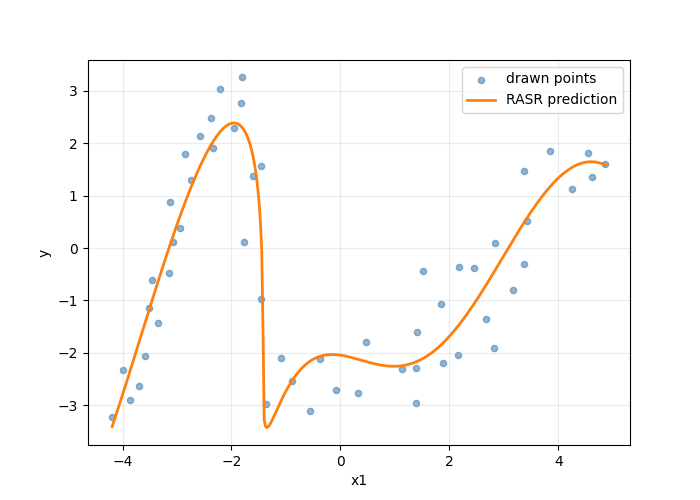

In [7]:
x_grid = np.linspace(X[:, 0].min(), X[:, 0].max(), 400).reshape(-1, 1)
y_grid_pred = model.predict(x_grid).reshape(-1)

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(X[:, 0], y, s=20, alpha=0.6, color="steelblue", label="drawn points")
ax.plot(x_grid[:, 0], y_grid_pred, color="tab:orange", linewidth=2, label="RASR prediction")
ax.set_xlabel("x1")
ax.set_ylabel("y")
ax.legend()
ax.grid(alpha=0.25)
plt.show()

### Fit vs. expression size

`fit()` samples many candidate expressions and refines their constants. Each candidate is scored
on fit, measured by $R^2$, and on expression size (the number of nodes in the expression tree).
`model.pareto_front_` holds the candidates not beaten on both axes at once. `get_expression()`
returns the candidate maximizing $R^2 - \gamma \cdot \text{size}$, where the parsimony weight
$\gamma$ (`parsimony` above) states how much additional fit a candidate must deliver to justify one
further node.

complexity   train R2  expression
        23     0.2445  1.9 * (sin(-3e+03 + 4.2e+02 * (-36 * x1 + 1.5e+02 * tanh(2.2 + 1.3 * x1) + 1.8e+02)) - 0.068) / 1.5 + -0.41
        26     0.8459  1.9 * (-0.84 + -0.9 * sin(0.32 + 0.9 * x1) + 1.1 * cos(-4.2 + -2.5 * pow1_3(-1.7 + -1.2 * x1))) / 0.77 + -0.41
        47     0.8737  1.9 * (0.13 + 1.4 * cos(-7 + -3.2 * (0.38 * x1 + -0.67 * pow1_3(1.9 + 1.4 * x1) + -2.5)) + -0.77 * cos(1.8 + 0.57 * (-0.66 * x1 + 1.4 * sin(-6.4 + 1.3 * x1) + 0.68))) / 0.64 + -0.41


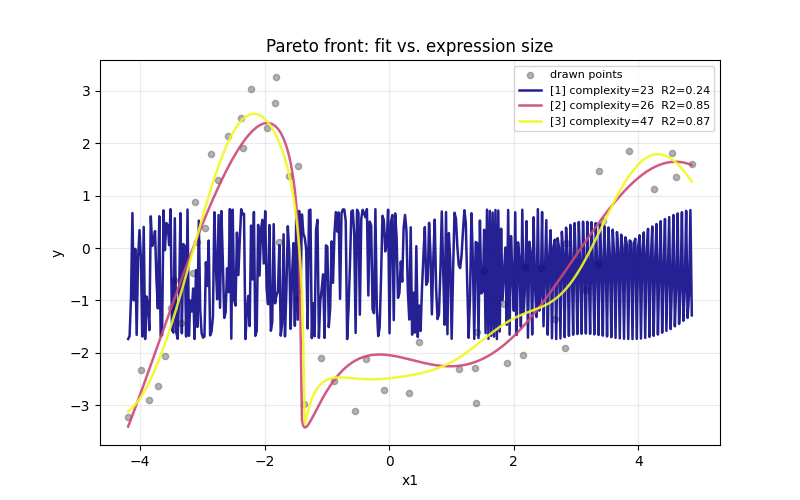

In [8]:
print(f"{'complexity':>10}  {'train R2':>9}  expression")
for c in model.pareto_front_:
    print(f"{c.complexity:>10}  {c.r2:>9.4f}  {c.expression_string}")

front = model.pareto_front_
n = len(front)
cmap = plt.get_cmap("plasma")
x_grid_std = (x_grid - model.X_mean_) / model.X_std_

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(X[:, 0], y, s=20, alpha=0.5, color="0.4", zorder=2, label="drawn points")
for i, candidate in enumerate(front):
    color = cmap(i / max(n - 1, 1))
    y_grid_candidate = candidate.refiner.predict(x_grid_std).reshape(-1) * model.y_std_scale_ + model.y_mean_
    label = f"[{i + 1}] complexity={candidate.complexity}  R2={candidate.r2:.2f}"
    ax.plot(x_grid[:, 0], y_grid_candidate, color=color, linewidth=1.8, alpha=0.9, label=label)
ax.set_xlabel("x1")
ax.set_ylabel("y")
ax.grid(alpha=0.25)
ax.legend(loc="best", fontsize=8)
ax.set_title("Pareto front: fit vs. expression size")
plt.show()

## 2. A real multivariate dataset

Here RASR is fit to scikit-learn's diabetes dataset (10 clinical features, no known ground-truth
expression) and evaluated on a held-out test split. Loaded with `as_frame=True`, the features keep
their column names (`age`, `bmi`, ...), and `variable_names="auto"` uses them in the expression
instead of `x1, x2, ...`.

To try your own data, replace `data.data` and `data.target` below. The model expects:

- at most 11 features, all numeric (encode categorical features first),
- no missing values,
- about 1,000 rows or fewer. Pre-training used datasets of 8 to 1024 rows, so fit larger datasets
  on a random subset of rows (the SRBench evaluation used 2048).

In [9]:
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split

data = load_diabetes(as_frame=True)
X_train2, X_test2, y_train2, y_test2 = train_test_split(
    data.data, data.target, test_size=0.2, random_state=0
)

model.fit(X_train2, y_train2, variable_names="auto")

y_pred_train2 = model.predict(X_train2).reshape(-1)
y_pred_test2 = model.predict(X_test2).reshape(-1)
print("Best expression:")
print(" ", model.get_expression(precision=2))
print(f"Train R2: {r2_score(y_train2, y_pred_train2):.4f}")
print(f"Test R2:  {r2_score(y_test2, y_pred_test2):.4f}")

Refining: 100%|██████████| 32/32 [00:11<00:00,  2.71it/s]

Best expression:
  78 * (-34 + -3.2e+03 * bmi + -1.3e+03 * bp + 1.2e+03 * s3 + -9.1e+02 * s5 + -1.6e+02 * sin(-2.9 + -22 * s5)) / -4.5e+02 + 1.5e+02
Train R2: 0.5329
Test R2:  0.3304


In [10]:
X_test2_std = (np.asarray(X_test2, dtype=np.float32) - model.X_mean_) / model.X_std_

print(f"{'complexity':>10}  {'train R2':>9}  {'test R2':>9}  expression")
for c in model.pareto_front_:
    y_pred_test2_c = c.refiner.predict(X_test2_std).reshape(-1) * model.y_std_scale_ + model.y_mean_
    test_r2 = r2_score(y_test2, y_pred_test2_c)
    print(f"{c.complexity:>10}  {c.r2:>9.4f}  {test_r2:>9.4f}  {c.expression_string}")

complexity   train R2    test R2  expression
        28     0.5329     0.3304  78 * (-34 + -3.2e+03 * bmi + -1.3e+03 * bp + 1.2e+03 * s3 + -9.1e+02 * s5 + -1.6e+02 * sin(-2.9 + -22 * s5)) / -4.5e+02 + 1.5e+02
        33     0.5418     0.3112  78 * (5.1e+02 + -8.3e+04 * s3 + 2e+05 * s5 + 2.3e+05 * bmi + 9.3e+04 * bp + 6.6e+03 * cos(-1.4 + 9.5 * sin(-0.98 + 3.3e+02 * s6))) / 3.1e+04 + 1.5e+02
        38     0.5469     0.3301  78 * (2.1 + 1.7e+02 * bmi + 12 * tanh(-0.32 + 22 * s5) + -63 * s3 + 72 * bp + -4.2 * sin(-7.1 + -5.7 * cos(0.42 + -2.2e+02 * age))) / 24 + 1.5e+02
        42     0.5589     0.2627  78 * (17 + 7.2e+02 * bmi + -4.3e+02 * s5 + -22 * cos(4.9 + -21 * sin(-2 + -80 * age)) + 3e+02 * bp + -2.1e+02 * s3 + -93 * cos(1.4 + 15 * s5)) / 99 + 1.5e+02
